# My two-model early results

I study whether human-rated Lichess difficulty predicts assisted exact first-move correctness. I use **GPT-OSS 120B** and **Gemini 3.5 Flash-Lite** on the same 60 puzzle positions. This notebook only reads my audited saved answers and fitted models; it makes no API calls.

I can run the two code cells below with the project `.venv` kernel to refresh my three figures. I keep historical collection notebooks as references and do not rerun the pilot to create a bulk sample.

## 1. I check my saved results

In [1]:

from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments/stage_index.json').exists())
FIG = ROOT / 'figures/early_results'
FIG.mkdir(exist_ok=True)
paths = {
    'GPT-OSS 120B': ('09_research_sample', '10_research_analysis'),
    'Gemini 3.5 Flash-Lite': ('11_additional_models/gemini', '11_additional_models/gemini'),
}
models = {}
for name, (collection, analysis) in paths.items():
    source = ROOT / 'data/experiments' / collection
    fitted = ROOT / 'data/analysis' / analysis
    audit = json.loads((source / 'audit.json').read_text())
    assert audit['passed']
    assert hashlib.sha256((source / 'results.csv').read_bytes()).hexdigest() == audit['results_sha256']
    data = pd.read_csv(source / 'results.csv', dtype={'puzzle_id': str})
    assert len(data) == 60 and data.puzzle_id.nunique() == 60
    assert data.status.eq('completed').all()
    models[name] = {
        'data': data,
        'fit': joblib.load(fitted / 'logistic_regression.joblib'),
        'tree': json.loads((fitted / 'decision_tree.json').read_text())['tree'],
        'coefficients': pd.read_csv(fitted / 'logistic_coefficients.csv'),
    }
assert set(models['GPT-OSS 120B']['data'].puzzle_id) == set(models['Gemini 3.5 Flash-Lite']['data'].puzzle_id)
summary = pd.DataFrame([
    {'Model': name, 'Puzzles': len(m['data']), 'Correct': int(m['data'].success.sum()),
     'Accuracy': f"{m['data'].success.mean():.1%}", 'Provider failures': 0}
    for name, m in models.items()
])
assert summary.Correct.tolist() == [21, 32]
display(summary)
print('I verified the saved result hashes and the shared 60 puzzle IDs. No API calls or refitting are performed.')


,Model,Puzzles,Correct,Accuracy,Provider failures
0,GPT-OSS 120B,60,21,35.0%,0
1,Gemini 3.5 Flash-Lite,60,32,53.3%,0


I verified the saved result hashes and the shared 60 puzzle IDs. No API calls or refitting are performed.


## 2. I review my figures

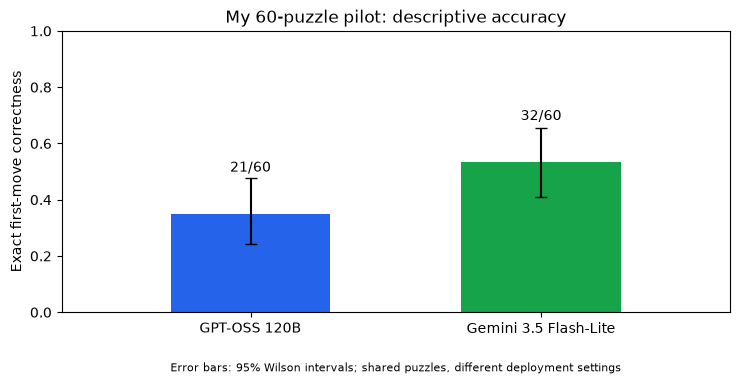

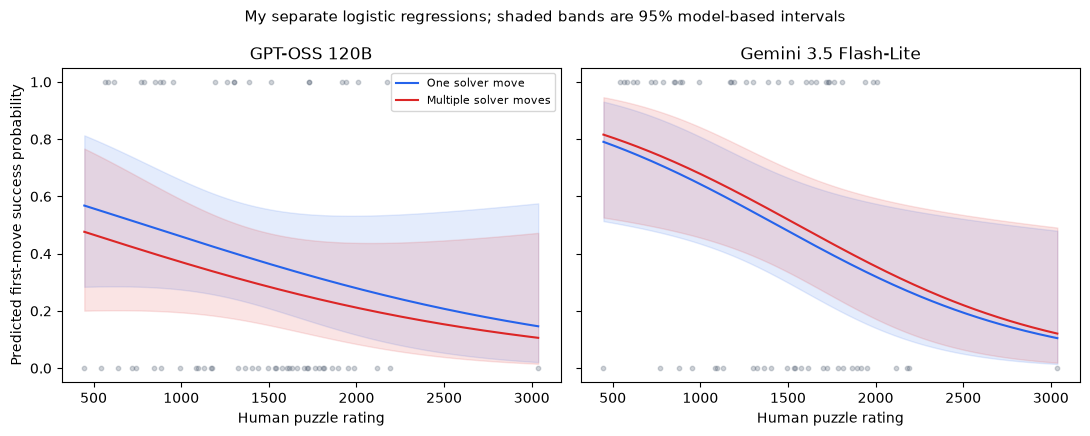

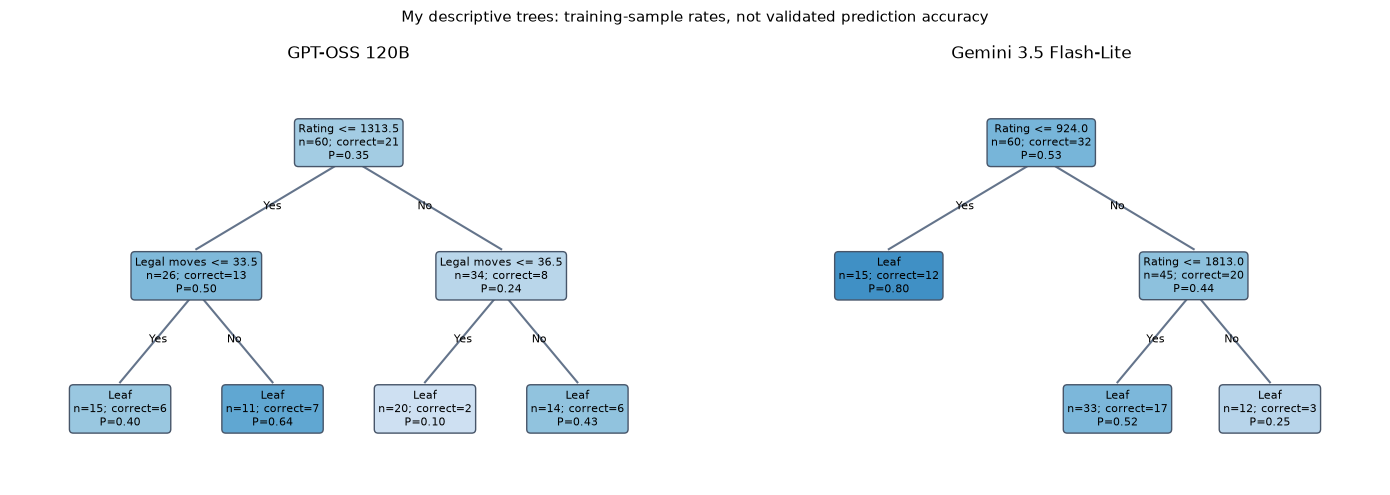

In [2]:

# I show the same outcomes and saved fits; each deployment is analyzed separately.
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, (name, m) in enumerate(models.items()):
    n = len(m['data']); correct = int(m['data'].success.sum()); p = correct / n; z = 1.96
    center = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    ax.bar(i, p, color=['#2563eb', '#16a34a'][i], width=.55)
    ax.errorbar(i, p, yerr=[[p-center+half], [center+half-p]], fmt='none', color='black', capsize=4)
    ax.text(i, p+.15, f'{correct}/{n}', ha='center')
ax.set(xticks=[0, 1], xticklabels=list(models), ylim=(0, 1), xlim=(-.65, 1.65),
       ylabel='Exact first-move correctness', title='My 60-puzzle pilot: descriptive accuracy')
ax.text(.5, -.21, 'Error bars: 95% Wilson intervals; shared puzzles, different deployment settings',
        ha='center', transform=ax.transAxes, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'accuracy.png', dpi=180); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    data = m['data']; rating = np.linspace(data.puzzle_rating.min(), data.puzzle_rating.max(), 200)
    for group, color, label in [(0, '#2563eb', 'One solver move'), (1, '#dc2626', 'Multiple solver moves')]:
        grid = pd.DataFrame({'const': np.ones(200), 'rating_500': (rating-1500)/500, 'multi_move': np.full(200, group)})
        prediction = m['fit'].get_prediction(grid).summary_frame()
        ax.plot(rating, prediction['mean'], color=color, label=label)
        ax.fill_between(rating, prediction['mean_ci_lower'], prediction['mean_ci_upper'], color=color, alpha=.12)
    ax.scatter(data.puzzle_rating, data.success, s=10, alpha=.25, color='#475569')
    ax.set(title=name, xlabel='Human puzzle rating', ylim=(-.05, 1.05))
axes[0].set_ylabel('Predicted first-move success probability'); axes[0].legend(fontsize=8)
fig.suptitle('My separate logistic regressions; shaded bands are 95% model-based intervals', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'logistic_regression.png', dpi=180); plt.show()

# I draw the saved depth-2 trees, without retraining or claiming test accuracy.
feature_names = {'puzzle_rating': 'Rating', 'total_solver_moves': 'Solver moves', 'legal_moves': 'Legal moves'}
def draw_tree(ax, node, x=.5, width=.45, depth=0, parent=None, branch=None):
    y = 1-depth*.35
    if parent:
        ax.plot([parent[0], x], [parent[1]-.04, y+.07], color='#64748b', zorder=0)
        ax.text((parent[0]+x)/2, (parent[1]+y)/2, branch, ha='center', fontsize=8)
    title = f"{feature_names[node['feature']]} <= {node['threshold']:.1f}" if 'feature' in node else 'Leaf'
    text = title + f"\nn={node['n']}; correct={node['correct']}\nP={node['probability']:.2f}"
    ax.text(x, y, text, ha='center', va='center', fontsize=8,
            bbox={'boxstyle': 'round,pad=.35', 'facecolor': plt.cm.Blues(.15+.6*node['probability']), 'edgecolor': '#475569'})
    if 'feature' in node:
        draw_tree(ax, node['left'], x-width/2, width/2, depth+1, (x, y), 'Yes')
        draw_tree(ax, node['right'], x+width/2, width/2, depth+1, (x, y), 'No')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, m) in zip(axes, models.items()):
    ax.set_axis_off(); ax.set(xlim=(0, 1), ylim=(.1, 1.2), title=name); draw_tree(ax, m['tree'])
fig.suptitle('My descriptive trees: training-sample rates, not validated prediction accuracy', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'decision_trees.png', dpi=180); plt.show()


## My interpretation and next steps

I recorded **21/60 correct (35%)** for GPT-OSS and **32/60 (53.3%)** for Gemini. Both returned all 60 responses without provider failures. My audited scorer counts format failures as unsuccessful answers.

For Gemini, my rating odds ratio is **0.51 per 500 points** (95% model-based interval **0.29-0.90**), adjusting for the multiple-solver-moves indicator. For GPT-OSS it is **0.67** (interval **0.39-1.17**). These are early associations from a balanced assisted sample. I do not infer a causal model-family effect, full-sequence solving ability, or future prediction accuracy.

My pilot supports moving to bulk collection. Before starting, I will:

1. Freeze a new shared sample of 1,000 puzzles, excluding all previously exposed or reserved IDs, and record the sampling design and seed.
2. Freeze each deployment's existing prompt, settings, scoring and analysis plan. I will decide any holdout split before inspecting new answers.
3. Prepare a separate bulk notebook with provider-specific quota pacing, daily pause/resume, saved responses and immutable completed answers. My historical collectors are hardcoded to 60 cases and are not bulk-ready.
4. Run both providers on the same puzzles, audit the responses, then fit separate regressions. I will treat trees as descriptive unless I evaluate them on a held-out puzzle set.

I expect the free-tier run to span multiple days. My Gemini account shows 500 requests/day; Groq's published GPT-OSS allowance is 200,000 tokens/day. Based on pilot usage, I budget about 2 quota days for Gemini from an unused allowance and roughly 9-12 days for GPT-OSS, with extra room for checks and retries. I will verify current account limits before starting. I have not started a bulk run.
